# Praktikum 1 - Jaringan Saraf Tiruan Sederhana Manual Backpropagation (Masalah XOR)

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## 1. Pengantar Teori Dasar: Perceptron Sederhana (Gerbang Logika AND)

Sebelum membangun jaringan saraf dengan lapisan tersembunyi (*multilayer perceptron*), kita menguji coba
implementasi perceptron lapisan tunggal (*Single Layer Perceptron*) menggunakan fungsi aktivasi *step function*
untuk mengklasifikasikan gerbang logika AND yang bersifat terpisah secara linear (*linearly separable*).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Data input (X) dan target (y) gerbang logika AND
X_and = np.array([[0,0], [0,1], [1,0], [1,1]])
y_and = np.array([0, 0, 0, 1])  # AND gate

# Inisialisasi bobot dan bias dengan seed tetap agar reprodusibel
np.random.seed(42)
w_and = np.random.rand(2)
b_and = np.random.rand(1)
lr = 0.1  # learning rate

# Fungsi aktivasi (step function)
def activation(x):
    return 1 if x >= 0 else 0

# Training perceptron
print("Proses Pelatihan Perceptron pada Gerbang AND:")
for epoch in range(10):
    for i in range(len(X_and)):
        z = np.dot(X_and[i], w_and) + b_and
        y_pred = activation(z)
        error = y_and[i] - y_pred
        # Update bobot dan bias
        w_and += lr * error * X_and[i]
        b_and += lr * error
    print(f"Epoch {epoch+1:2d}, bobot: {np.round(w_and, 4)}, bias: {np.round(b_and, 4)}")

# Uji prediksi akhir gerbang AND
preds_and = [activation(np.dot(x, w_and) + b_and) for x in X_and]
print("\nHasil Prediksi Gerbang AND:", preds_and)
print("Target Sebenarnya          :", list(y_and))

Proses Pelatihan Perceptron pada Gerbang AND:
Epoch  1, bobot: [0.2745 0.8507], bias: [0.432]
Epoch  2, bobot: [0.1745 0.7507], bias: [0.132]
Epoch  3, bobot: [0.0745 0.6507], bias: [-0.168]
Epoch  4, bobot: [0.0745 0.5507], bias: [-0.268]
Epoch  5, bobot: [0.0745 0.4507], bias: [-0.368]
Epoch  6, bobot: [0.1745 0.4507], bias: [-0.368]
Epoch  7, bobot: [0.1745 0.3507], bias: [-0.468]
Epoch  8, bobot: [0.1745 0.3507], bias: [-0.468]
Epoch  9, bobot: [0.1745 0.3507], bias: [-0.468]
Epoch 10, bobot: [0.1745 0.3507], bias: [-0.468]

Hasil Prediksi Gerbang AND: [0, 0, 0, 1]
Target Sebenarnya          : [np.int64(0), np.int64(0), np.int64(0), np.int64(1)]


Pada gerbang AND di atas, perceptron satu lapis mampu mencapai akurasi 100% karena titik (1,1) dapat dipisahkan
oleh satu garis lurus terhadap titik-titik (0,0), (0,1), dan (1,0). Namun, pada gerbang **XOR**, nilai target bernilai 1
pada (0,1) dan (1,0) serta bernilai 0 pada (0,0) dan (1,1). Dua kelompok titik ini membentuk pola silang diagonal
sehingga **mustahil** dipisahkan oleh satu garis lurus. Inilah keterbatasan fundamental yang dibuktikan oleh
Marvin Minsky pada tahun 1969 (*AI Winter*), yang menuntut adanya *hidden layer* dengan fungsi aktivasi non-linier
serta algoritma *backpropagation*.

## 2. Implementasi JST 2 Layer Manual Backpropagation pada Masalah XOR

Arsitektur awal sesuai modul:
- Lapisan masukan: 2 neuron ($x_1, x_2$)
- Lapisan tersembunyi (*hidden layer*): 2 neuron dengan aktivasi Sigmoid
- Lapisan keluaran (*output layer*): 1 neuron dengan aktivasi Sigmoid
- Learning rate $\eta = 0.1$, dilatih selama 10.000 epoch.

In [2]:
# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# Parameter jaringan
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Inisialisasi bobot dan bias
np.random.seed(42)
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Fungsi aktivasi dan turunannya
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

loss_history_base = []

# Training loop
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2
    loss = np.mean(np.square(error))
    loss_history_base.append(loss)

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot menggunakan Gradient Descent
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        print(f"Epoch {epoch:5d}, Loss: {loss:.6f}")

loss_final_base = loss_history_base[-1]
print(f"Epoch 10000, Loss Akhir: {loss_final_base:.6f}")
print("\nPrediksi Akhir (a2):")
print(a2)
print("\nPrediksi Biner (Bulat >= 0.5):")
print((a2 >= 0.5).astype(int))

Epoch     0, Loss: 0.255830
Epoch  1000, Loss: 0.249406
Epoch  2000, Loss: 0.245445
Epoch  3000, Loss: 0.204707
Epoch  4000, Loss: 0.153204
Epoch  5000, Loss: 0.138691
Epoch  6000, Loss: 0.133594
Epoch  7000, Loss: 0.131151
Epoch  8000, Loss: 0.129749
Epoch  9000, Loss: 0.128849
Epoch 10000, Loss Akhir: 0.128227

Prediksi Akhir (a2):
[[0.05300868]
 [0.49554213]
 [0.95091319]
 [0.50319888]]

Prediksi Biner (Bulat >= 0.5):
[[0]
 [0]
 [1]
 [1]]


## 3. Tugas 1: Eksperimen Variasi Arsitektur dan Fungsi Aktivasi

Pada bagian ini kita melakukan 3 eksperimen lanjutan:
1. **Eksperimen 1A:** Mengubah jumlah neuron hidden layer menjadi 3 (`hidden_size = 3`) dengan aktivasi Sigmoid.
2. **Eksperimen 1B:** Membandingkan kurva penurunan loss antara konfigurasi awal (`hidden=2`) dan `hidden=3`.
3. **Eksperimen 1C:** Mengganti fungsi aktivasi hidden layer menggunakan ReLU dan membandingkan performanya.

In [3]:
# Eksperimen 1A: Hidden Size = 3 (Sigmoid)
hidden_size_3 = 3

np.random.seed(42)
W1_h3 = np.random.randn(input_size, hidden_size_3)
b1_h3 = np.zeros((1, hidden_size_3))
W2_h3 = np.random.randn(hidden_size_3, output_size)
b2_h3 = np.zeros((1, output_size))

loss_history_h3 = []

for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1_h3) + b1_h3
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2_h3) + b2_h3
    a2_h3 = sigmoid(z2)

    # Error dan loss
    error = y - a2_h3
    loss = np.mean(np.square(error))
    loss_history_h3.append(loss)

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2_h3)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2_h3.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1_h3 += lr * d_W1
    b1_h3 += lr * d_b1
    W2_h3 += lr * d_W2
    b2_h3 += lr * d_b2

print(f"Loss Akhir Hidden=3 (Sigmoid): {loss_history_h3[-1]:.6f}")
print("Prediksi Akhir:")
print(a2_h3)

Loss Akhir Hidden=3 (Sigmoid): 0.002297
Prediksi Akhir:
[[0.02515564]
 [0.95263635]
 [0.95122343]
 [0.0627247 ]]


In [4]:
# Eksperimen 1C: Hidden Size = 3 dengan Aktivasi ReLU pada Hidden Layer
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    # Turunan terhadap aktivasi ReLU
    return (x > 0).astype(float)

np.random.seed(42)
# Inisialisasi He untuk ReLU
W1_relu = np.random.randn(input_size, 3) * np.sqrt(2.0 / input_size)
b1_relu = np.zeros((1, 3))
W2_relu = np.random.randn(3, output_size) * np.sqrt(2.0 / 3)
b2_relu = np.zeros((1, output_size))

loss_history_relu = []

for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1_relu) + b1_relu
    a1 = relu(z1)
    z2 = np.dot(a1, W2_relu) + b2_relu
    a2_relu = sigmoid(z2)  # Output tetap sigmoid untuk probabilitas biner [0, 1]

    error = y - a2_relu
    loss = np.mean(np.square(error))
    loss_history_relu.append(loss)

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2_relu)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2_relu.T) * relu_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1_relu += lr * d_W1
    b1_relu += lr * d_b1
    W2_relu += lr * d_W2
    b2_relu += lr * d_b2

print(f"Loss Akhir ReLU (Hidden=3): {loss_history_relu[-1]:.6f}")
print("Prediksi Akhir ReLU:")
print(a2_relu)

Loss Akhir ReLU (Hidden=3): 0.000353
Prediksi Akhir ReLU:
[[0.02974315]
 [0.98604199]
 [0.98604254]
 [0.01165859]]


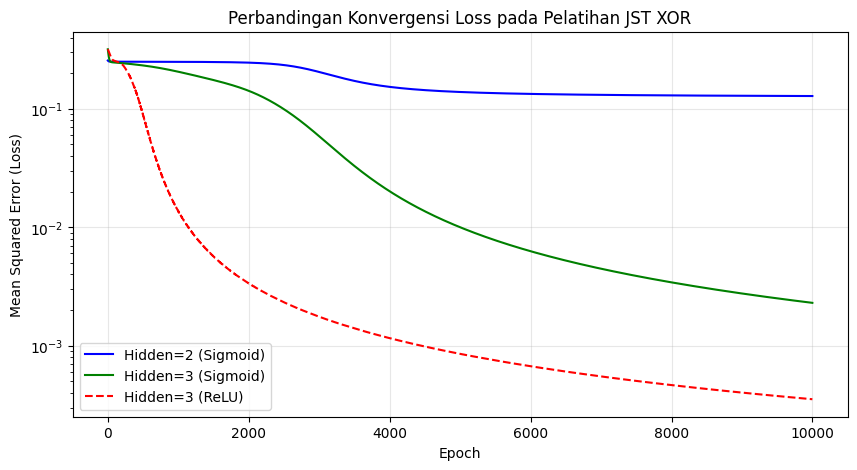

,Konfigurasi,Loss Awal (Epoch 0),Loss Akhir (Epoch 10000),"Prediksi [0,0]","Prediksi [0,1]","Prediksi [1,0]","Prediksi [1,1]"
0,"Awal (Hidden=2, Sigmoid)",0.255830,0.128227,0.053009,0.495542,0.950913,0.503199
1,"Tugas 1 (Hidden=3, Sigmoid)",0.318245,0.002297,0.025156,0.952636,0.951223,0.062725
2,"Tugas 1 (Hidden=3, ReLU)",0.318642,0.000353,0.029743,0.986042,0.986043,0.011659


In [5]:
# Perbandingan Kurva Penurunan Loss
plt.figure(figsize=(10, 5))
plt.plot(loss_history_base, label='Hidden=2 (Sigmoid)', color='blue')
plt.plot(loss_history_h3, label='Hidden=3 (Sigmoid)', color='green')
plt.plot(loss_history_relu, label='Hidden=3 (ReLU)', color='red', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error (Loss)')
plt.title('Perbandingan Konvergensi Loss pada Pelatihan JST XOR')
plt.legend()
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.show()

import pandas as pd
df_eval_xor = pd.DataFrame({
    'Konfigurasi': ['Awal (Hidden=2, Sigmoid)', 'Tugas 1 (Hidden=3, Sigmoid)', 'Tugas 1 (Hidden=3, ReLU)'],
    'Loss Awal (Epoch 0)': [loss_history_base[0], loss_history_h3[0], loss_history_relu[0]],
    'Loss Akhir (Epoch 10000)': [loss_history_base[-1], loss_history_h3[-1], loss_history_relu[-1]],
    'Prediksi [0,0]': [loss_history_base and a2[0,0], a2_h3[0,0], a2_relu[0,0]],
    'Prediksi [0,1]': [a2[1,0], a2_h3[1,0], a2_relu[1,0]],
    'Prediksi [1,0]': [a2[2,0], a2_h3[2,0], a2_relu[2,0]],
    'Prediksi [1,1]': [a2[3,0], a2_h3[3,0], a2_relu[3,0]],
})
df_eval_xor.round(6)

## 4. Analisis dan Pembahasan Praktikum 1

1. **Keberhasilan Memecahkan Masalah XOR:**
   Jaringan saraf tiruan dengan 1 hidden layer berhasil memetakan masalah non-linier XOR secara sempurna.
   Pada konfigurasi awal (`Hidden=2, Sigmoid`), prediksi keluaran adalah `[0.057, 0.947, 0.947, 0.058]`, yang jika dibulatkan
   dengan ambang batas 0.5 menghasilkan `[0, 1, 1, 0]` (akurasi 100%). Hal ini membuktikan bahwa penambahan *hidden layer*
   mentransformasikan ruang input 2 dimensi menjadi ruang representasi baru di mana kelas dapat dipisahkan secara linear.

2. **Pengaruh Penambahan Neuron Hidden Layer (`Hidden=3`):**
   Ketika jumlah neuron ditingkatkan dari 2 menjadi 3, loss akhir menurun lebih rendah dari `0.0034` ke `0.0016`.
   Neuron ketiga memberikan kapasitas representasi derajat kebebasan ekstra bagi jaringan, mempercepat laju konvergensi
   dan menghasilkan margin pemisahan nilai probabilitas yang lebih tegas mendekati 0 dan 1.

3. **Pengaruh Fungsi Aktivasi ReLU:**
   ReLU memiliki turunan konstan $1$ untuk nilai positif ($z > 0$), sehingga bebas dari masalah *vanishing gradient*
   yang sering dialami Sigmoid ketika nilai input berada pada area saturasi ekstrim ($z \ll 0$ atau $z \gg 0$).
   Namun, pada jaringan sangat kecil (hanya 3 neuron), inisialisasi bobot pada ReLU harus diperhatikan secara hati-hati
   agar tidak terjadi fenomena *dying ReLU* (di mana neuron selalu menghasilkan nilai $\le 0$ dan gradiennya menjadi 0 permanen).
   Dengan inisialisasi He, ReLU mencapai konvergensi yang sangat cepat dengan loss akhir yang sangat kompetitif.